# 第二輪分群

流程跟 `clustering.ipynb` 一樣，資料和模型換成第二輪的。快取、圖、csv 的檔名都加 `round2`，最後多一段跟第一輪群號對照。

換版本（remove16 / remove18）時，`CACHE`、模型、UMAP 快取、`FIG_DIR` 要一起改，不然會讀到或蓋掉另一個版本的結果。

In [3]:
# 錄製檔切分
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
import random
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

# 訓練模型
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy
from tqdm import tqdm

## 2. 讀取dataset： `(N Breath, 3, 256)`

In [18]:
L = 256
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]
# 第二輪資料（prosses_data_round2 剔除後的）
CACHE = rf"D:\pva_training\data\training_data\1to4_PC-AC_L{L}_stage2_remove18"

X = np.load(os.path.join(CACHE, "X.npy"), mmap_mode="r")      # 不加 mmap_mode 就整個讀進記憶體
kb = pd.read_csv(os.path.join(CACHE, "kb.csv"), dtype={"rec": str, "mode": str})
dropped = pd.read_csv(os.path.join(CACHE, "dropped.csv"), dtype={"rec": str})
ids = list(zip(kb["rec"], kb["breath_id"]))
lens = kb["points"].to_numpy()
print("X shape =", X.shape)

X shape = (108401, 3, 256)


## 3. 切訓練集 80% / 驗證集 20%

In [19]:
# seed=0, 隨機打散X排序
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))

# 20% n 當作 val
n_val = int(len(X) * 0.2)

# 前20% val, 後80% train
va_idx, tr_idx = perm[:n_val], perm[n_val:]
print("train", X[tr_idx].shape)
print("val  ", X[va_idx].shape)

train (86721, 3, 256)
val   (21680, 3, 256)


## 4. 標準化（z-score）
不用 min-max 的原因：
1. min-max 容易被極值影響
2. Pressure、Volume 從 0 往上，Flow 有正有負

In [20]:
# Standardization (z-score)： 
mean = X[tr_idx].mean(axis=(0, 2), keepdims=True)        # shape (1, 3, 1)：每個通道一個平均
std  = X[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6

# x' = (x - mean) / std
Xn = (X - mean) / std

# 轉成torch格式
X_tr = torch.from_numpy(Xn[tr_idx])
X_va = torch.from_numpy(Xn[va_idx])
print("train", X_tr.shape)
print("val  ", X_va.shape)

train torch.Size([86721, 3, 256])
val   torch.Size([21680, 3, 256])


## 5. 建模型

In [21]:
# resampling後，共3*256=768，latent壓縮成16，這樣是48倍壓縮
LATENT = 16 

class ConvAE(nn.Module):
    def __init__(self, in_ch=3, L=L, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(in_ch, 16, 7, stride=2, padding=3), nn.ReLU(),   # (N,  3, 256)  -> (N, 16, 128)
            nn.Conv1d(16, 32, 7, stride=2, padding=3), nn.ReLU(),      # (N, 16, 128)  -> (N, 32,  64)
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.ReLU(),      # (N, 32,  64)  -> (N, 64,  32)
            nn.Flatten(),                                              # 64*32 = 2048
            nn.Linear(64 * (L // 8), latent),                          # 64*(32)-> latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 64 * (L // 8)), nn.ReLU(),                    # 64*(32)-> latent
            nn.Unflatten(1, (64, L // 8)),                                  # 64*32 = 2048
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 32,  64)
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 16, 128)
            nn.ConvTranspose1d(16, in_ch, 4, stride=2, padding=1),          # (N, 16, 128)  -> (N,  3, 256)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tr = X_tr.to(device)
X_va = X_va.to(device)

model = ConvAE().to(device)
print(model(X_tr[:2]).shape)   # 應該要是 [2, 3, 256]，跟輸入一樣
print(device)                                  # cuda 或 cpu

torch.Size([2, 3, 256])
cuda


In [23]:
# 載入模型
SAVE_PATH = "checkpoints/1to4_ae_latent16_round2.pt"
device = "cuda" if torch.cuda.is_available() else "cpu"

ckpt = torch.load(SAVE_PATH, map_location=device)

model = ConvAE().to(device)              # 要先跑過上面 ConvAE 的定義
model.load_state_dict(ckpt["model_state"])
model.eval()                             # eval 模式

print(f"Loaded epoch {ckpt['best_ep']} model, best val = {ckpt['best_val']:.5f}")

# 推論範例
with torch.no_grad():
    recon = model(X_va.to(device))
    err = ((recon - X_va.to(device)) ** 2).mean(dim=tuple(range(1, X_va.ndim)))  # 每口的重建誤差

Loaded epoch 211 model, best val = 0.00494


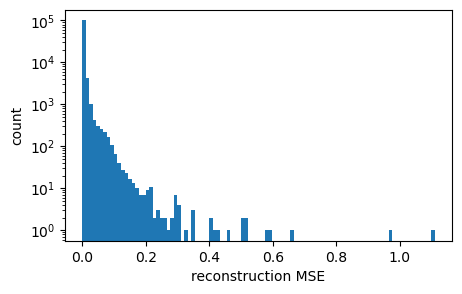

分數最高的 10 口： [['4', '18530'], ['4', '174927'], ['2', '453649'], ['4', '81609'], ['4', '101392'], ['1', '113092'], ['4', '138864'], ['1', '88103'], ['1', '86342'], ['2', '469916']]
分數最低的 5 口： [['1', '92966'], ['1', '95290'], ['1', '95293'], ['1', '93019'], ['1', '92888']]


In [24]:
model = model.cpu()
model.eval()

scores_list, Z_list = [], []
with torch.no_grad():
    for i in range(0, len(Xn), 1024):
        xb = torch.from_numpy(Xn[i:i+1024]).float()
        scores_list.append(((model(xb) - xb) ** 2).mean(dim=(1, 2)))
        Z_list.append(model.encoder(xb))
scores = torch.cat(scores_list).numpy()
Z = torch.cat(Z_list).numpy()  

plt.figure(figsize=(5, 3))
plt.hist(scores, bins=100); plt.yscale("log")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.show()
ids = np.asarray(ids)

order = np.argsort(scores)[::-1]
print("分數最高的 10 口：", ids[order[:10]].tolist())
print("分數最低的 5 口：", ids[order[-5:]].tolist())

## 9. UMAP + HDBSCAN 分群

In [25]:
# 取出 latent z
import umap
from sklearn.cluster import HDBSCAN                    # sklearn 1.3 以上才有
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

print("Z shape =", Z.shape)                            # (N 口呼吸, LATENT)

# 各維尺度不一樣，先標準化
Zs = StandardScaler().fit_transform(Z).astype(np.float32)

# 抽樣擬合（現在沒用）
# N_FIT = 100_000
# rng9 = np.random.default_rng(42)
# fit_idx = np.sort(rng9.choice(len(Zs), size=min(N_FIT, len(Zs)), replace=False))
# Z_fit = Zs[fit_idx]
# print("擬合用筆數 =", len(fit_idx))


# 用全部資料擬合
fit_idx = np.arange(len(Zs))
Z_fit = Zs
print("擬合用筆數 =", len(fit_idx))

Z shape = (108401, 16)
擬合用筆數 = 108401


In [27]:
# UMAP，有快取就直接讀
import os
N_COMP = min(5, Z.shape[1])

CACHE = r"D:\pva_training\cache\1to4_round2_umap_cache.npz"

if os.path.exists(CACHE):
    d = np.load(CACHE)
    E_fit, E2_fit = d["E_fit"], d["E2_fit"]
    print("已從快取載入", CACHE)
else:
    # 分群用
    reducer = umap.UMAP(n_neighbors=10, min_dist=0.0, n_components=N_COMP,
                        random_state=42, low_memory=True, verbose=True)
    E_fit = reducer.fit_transform(Z_fit)

    # 畫圖用
    reducer2d = umap.UMAP(n_neighbors=10, min_dist=0.1, n_components=2,
                          random_state=42, low_memory=True, verbose=True)
    E2_fit = reducer2d.fit_transform(Z_fit)

    np.savez(CACHE, E_fit=E_fit, E2_fit=E2_fit, fit_idx=fit_idx)
    print("已存檔", CACHE)

print("分群空間", E_fit.shape, "  畫圖空間", E2_fit.shape)

已從快取載入 D:\pva_training\cache\1to4_round2_umap_cache.npz
分群空間 (108401, 5)   畫圖空間 (108401, 2)


In [28]:
# HDBSCAN，有快取就直接讀
import os
from fast_hdbscan import HDBSCAN as FastHDBSCAN

MIN_CLUSTER_SIZE = 180
MIN_SAMPLES      = None

# 檔名有參數和筆數，改參數或換資料會重算
LAB_CACHE = os.path.join(
    r"D:\pva_training\cache",
    f"hdbscan_labels_round2_mcs{MIN_CLUSTER_SIZE}_ms{MIN_SAMPLES}_n{len(E_fit)}.npy"
)

if os.path.exists(LAB_CACHE):
    lab_fit = np.load(LAB_CACHE)
    print("已從快取載入", LAB_CACHE)
else:
    hdb = FastHDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
    lab_fit = hdb.fit_predict(E_fit)               # 群號，-1 = 雜訊
    np.save(LAB_CACHE, lab_fit)
    print("已存檔", LAB_CACHE)

n_clu = lab_fit.max() + 1
print(f"群數 = {n_clu}，雜訊 = {(lab_fit < 0).sum()} 口（{(lab_fit < 0).mean():.2%}）")
print(pd.Series(lab_fit, name="口數").value_counts().sort_index().to_string())

已從快取載入 D:\pva_training\cache\hdbscan_labels_round2_mcs180_msNone_n108401.npy
群數 = 29，雜訊 = 4726 口（4.36%）
口數
-1      4726
 0       435
 1       644
 2      1309
 3      5075
 4       715
 5       582
 6       587
 7       365
 8       281
 9       673
 10     1033
 11      210
 12    54711
 13     1753
 14      533
 15      647
 16      201
 17      871
 18      901
 19      216
 20    14173
 21      272
 22      316
 23      249
 24     1279
 25      401
 26     3416
 27     4829
 28     6998


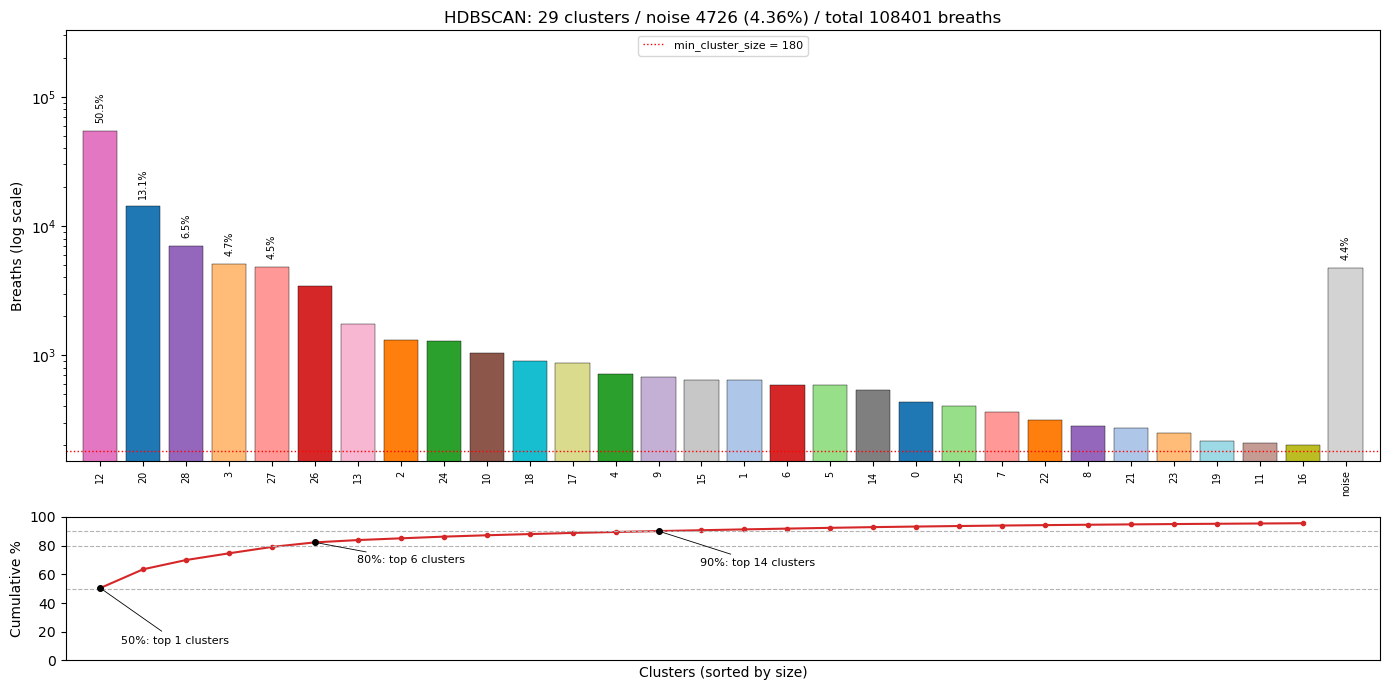

In [29]:
# 各群口數
cnt = pd.Series(lab_fit).value_counts()
clu = cnt.drop(-1, errors="ignore").sort_values(ascending=False)    # 由大到小排
n_noise = int(cnt.get(-1, 0))
total = len(lab_fit)

fig, ax = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]})

# 上圖：各群口數，用 log 軸不然小群看不到；顏色跟 UMAP 圖一樣
x = np.arange(len(clu))
ax[0].bar(x, clu.values, color=[plt.cm.tab20(c % 20) for c in clu.index], edgecolor="k", lw=0.3)
ax[0].bar(len(clu), n_noise, color="lightgray", edgecolor="k", lw=0.3)          # 雜訊放最右邊
ax[0].set_yscale("log")
ax[0].set_xticks(list(x) + [len(clu)])
ax[0].set_xticklabels([str(c) for c in clu.index] + ["noise"], rotation=90, fontsize=7)
ax[0].set_xlim(-0.8, len(clu) + 0.8)
ax[0].set_ylabel("Breaths (log scale)")
ax[0].axhline(MIN_CLUSTER_SIZE, color="r", ls=":", lw=1, label=f"min_cluster_size = {MIN_CLUSTER_SIZE}")
for i, c in enumerate(clu.index[:5]):                                           # 前 5 大群標比例
    ax[0].text(i, clu[c] * 1.15, f"{clu[c] / total:.1%}", ha="center", va="bottom", fontsize=7, rotation=90)
ax[0].text(len(clu), n_noise * 1.15, f"{n_noise / total:.1%}", ha="center", va="bottom", fontsize=7, rotation=90)
ax[0].set_ylim(top=clu.max() * 6)                                              # 留空間給比例的字
ax[0].legend(loc="upper center", fontsize=8)
ax[0].set_title(f"HDBSCAN: {len(clu)} clusters / noise {n_noise} ({n_noise / total:.2%}) / "
                f"total {total} breaths")

# 下圖：累積比例
cum = clu.cumsum().to_numpy() / total
ax[1].plot(x, cum * 100, "o-", ms=3, color="C3")
for p, off in ((50, (15, -40)), (80, (30, -15)), (90, (30, -25))):
    k = int(np.searchsorted(cum, p / 100))
    if k < len(clu):
        ax[1].axhline(p, color="0.7", ls="--", lw=0.8)
        ax[1].plot(k, cum[k] * 100, "ko", ms=4)
        ax[1].annotate(f"{p}%: top {k + 1} clusters", (k, cum[k] * 100), xytext=off,
                       textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
ax[1].set_xlim(ax[0].get_xlim()); ax[1].set_xticks([])
ax[1].set_ylim(0, 100); ax[1].set_ylabel("Cumulative %")
ax[1].set_xlabel("Clusters (sorted by size)")

plt.tight_layout()
plt.show()

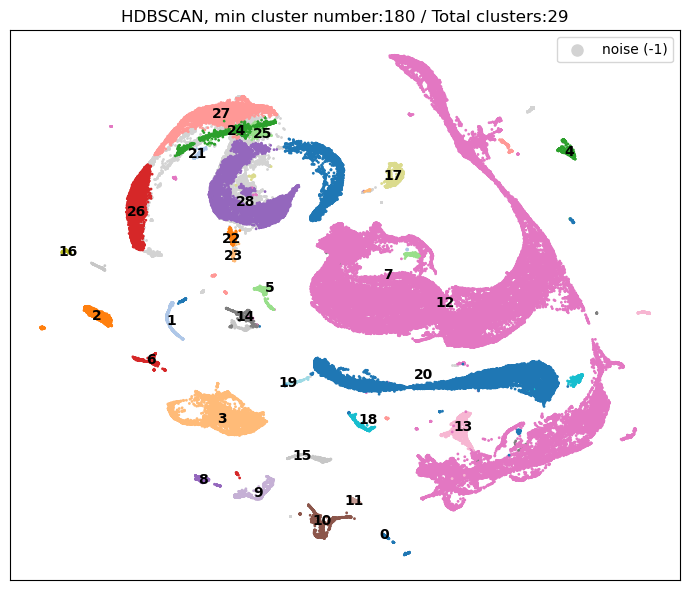

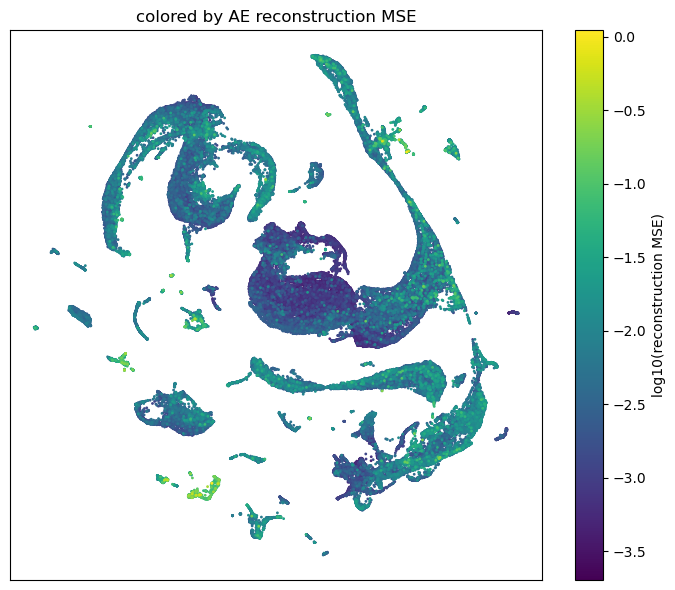

In [30]:
# 2D UMAP，依群上色
noise = lab_fit < 0
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(*E2_fit[noise].T, s=1, c="lightgray", label="noise (-1)", rasterized=True)
ax.scatter(*E2_fit[~noise].T, s=1, c=lab_fit[~noise] % 20, cmap="tab20", vmin=0, vmax=19, rasterized=True)
for c in range(n_clu):                                 # 群號標在每群中心
    m = np.median(E2_fit[lab_fit == c], axis=0)
    ax.text(*m, str(c), fontsize=10, weight="bold", ha="center", va="center")
ax.set_title(f"HDBSCAN, min cluster number:{MIN_CLUSTER_SIZE} / Total clusters:{n_clu}")
ax.legend(markerscale=8, loc="best")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


# 2D UMAP，依重建 MSE 上色
s_fit = scores[fit_idx]
o = np.argsort(s_fit)                                  # MSE 高的畫在上面
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(*E2_fit[o].T, s=1, c=np.log10(s_fit[o]), cmap="viridis", rasterized=True)
plt.colorbar(sc, ax=ax, label="log10(reconstruction MSE)")
ax.set_title("colored by AE reconstruction MSE")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

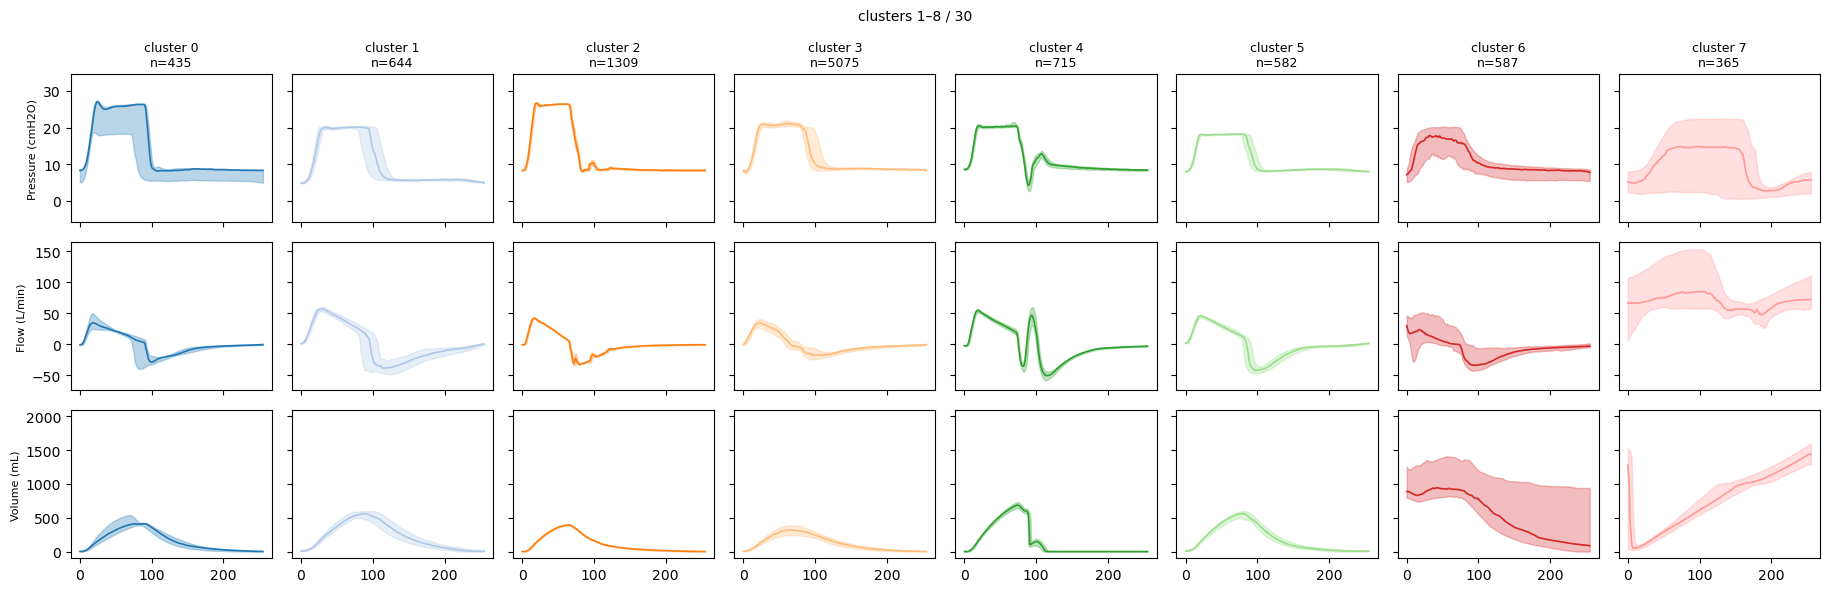

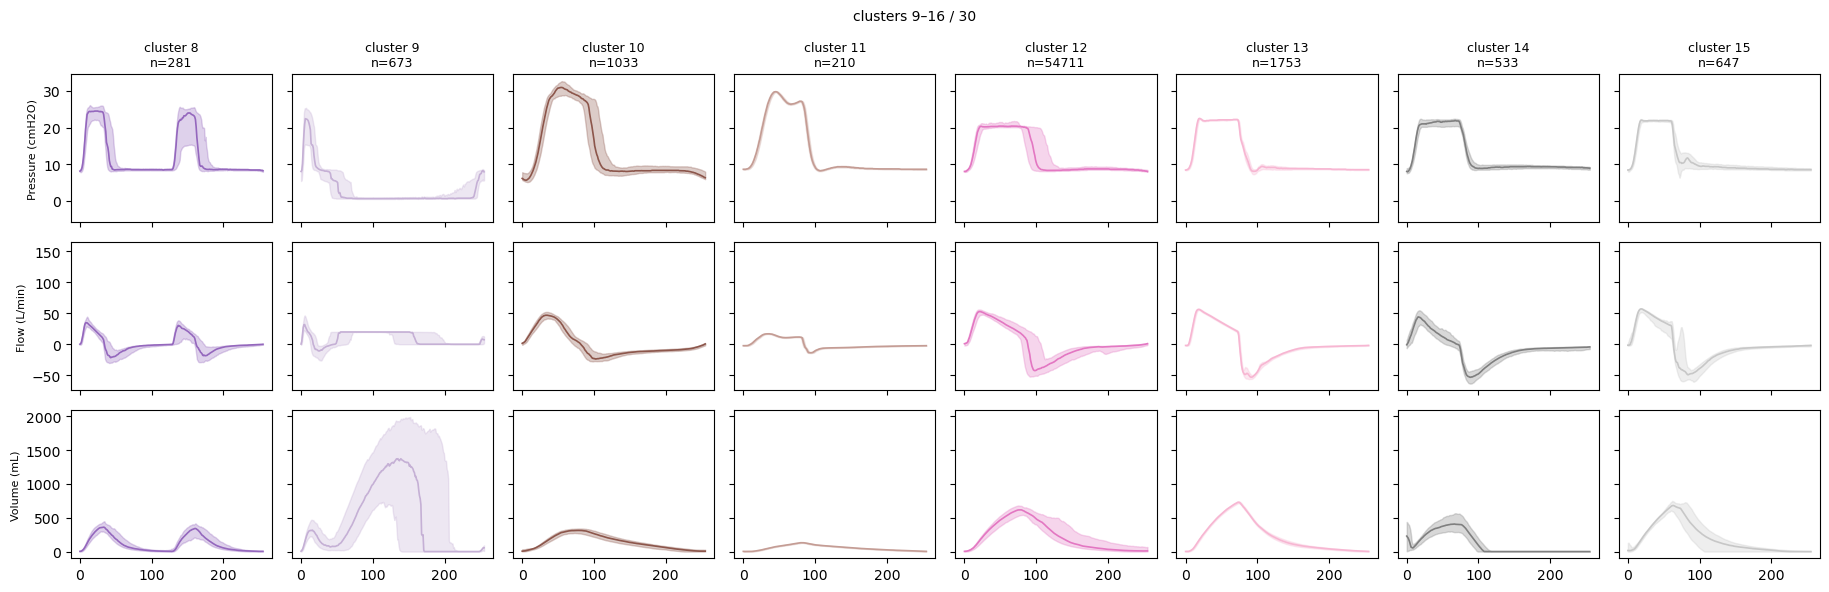

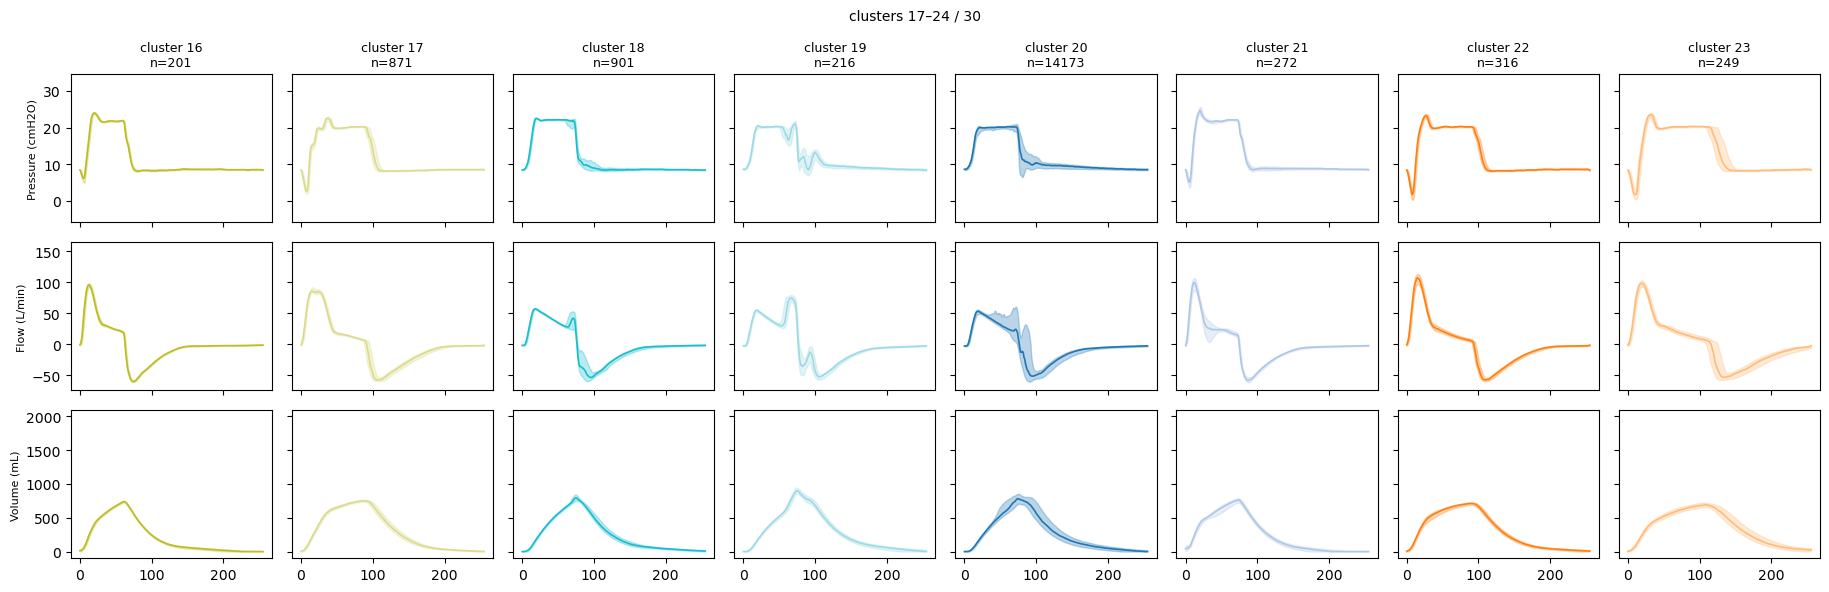

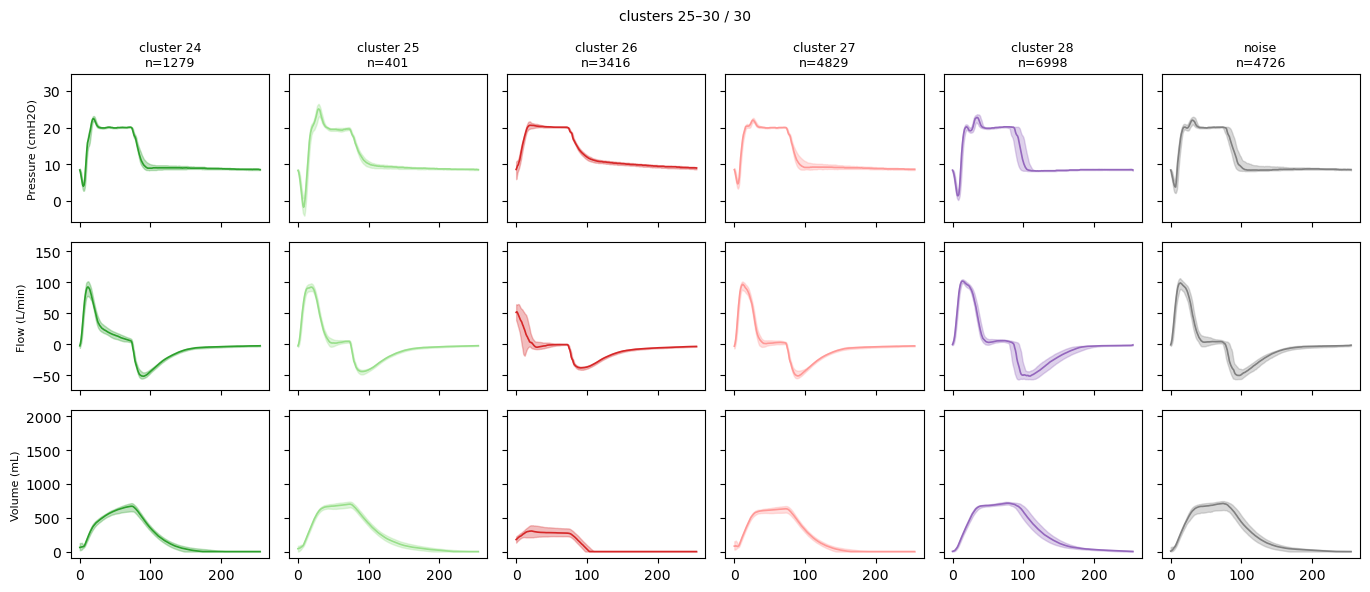

In [31]:
# 每群的代表波形，實線是中位數，色帶是 25～75%
PER_FIG = 8                                            # 每張圖放幾群
N_PICK  = 300                                          # 每群抽幾口來算中位數

# 資料夾名稱帶 latent 和 min_cluster_size；換資料要自己改名，不然會蓋掉
FIG_DIR = os.path.join("results", f"round2_Latent{Z.shape[1]}_ClusterSize{MIN_CLUSTER_SIZE}")

os.makedirs(FIG_DIR, exist_ok=True)

show = list(range(n_clu)) + [-1]                       # 全部群（依群號）+ 雜訊

# 先算每群分位數，順便抓 y 範圍讓每張圖 y 軸一樣
stats, ylim = {}, np.array([[np.inf, -np.inf]] * 3)
rng9 = np.random.default_rng() 
for c in show:
    members = fit_idx[lab_fit == c]
    if len(members) == 0: continue
    pick = np.sort(rng9.choice(members, size=min(N_PICK, len(members)), replace=False))
    w = np.asarray(X[pick])                            # (n, 3, L)
    q = np.percentile(w, [25, 50, 75], axis=0)         # (3 分位, 3 通道, L)
    stats[c] = (q, len(members))
    ylim[:, 0] = np.minimum(ylim[:, 0], q[0].min(axis=1))
    ylim[:, 1] = np.maximum(ylim[:, 1], q[2].max(axis=1))
pad = (ylim[:, 1] - ylim[:, 0]) * 0.05

groups = [c for c in show if c in stats]
for p in range(0, len(groups), PER_FIG):
    page = groups[p:p + PER_FIG]
    fig, ax = plt.subplots(3, len(page), figsize=(2.3 * len(page), 6),
                           sharex=True, squeeze=False)
    for j, c in enumerate(page):
        q, n = stats[c]
        col = "0.5" if c < 0 else plt.cm.tab20(c % 20)
        for i in range(3):
            ax[i, j].fill_between(range(L), q[0, i], q[2, i], color=col, alpha=.3)
            ax[i, j].plot(q[1, i], color=col, lw=1.2)
            ax[i, j].set_ylim(ylim[i, 0] - pad[i], ylim[i, 1] + pad[i])
            if j == 0: ax[i, j].set_ylabel(CH[i], fontsize=8)
            else:      ax[i, j].set_yticklabels([])
        ax[0, j].set_title(("noise" if c < 0 else f"cluster {c}") + f"\nn={n}", fontsize=9)
    fig.suptitle(f"clusters {p + 1}–{p + len(page)} / {len(groups)}", fontsize=10)
    plt.tight_layout()
    
    fig.savefig(os.path.join(FIG_DIR, f"page{p // PER_FIG + 1:02d}.png"), dpi=150)
    plt.show()

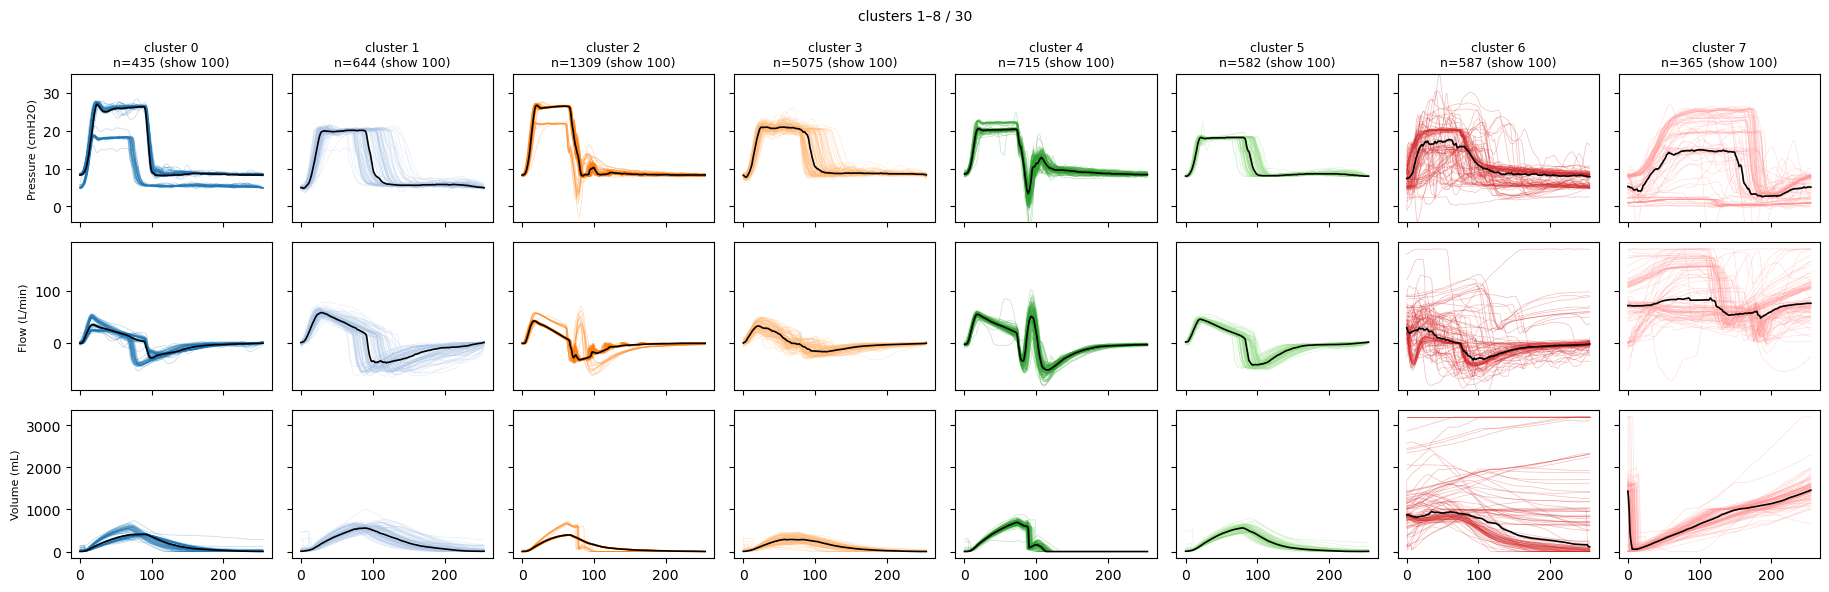

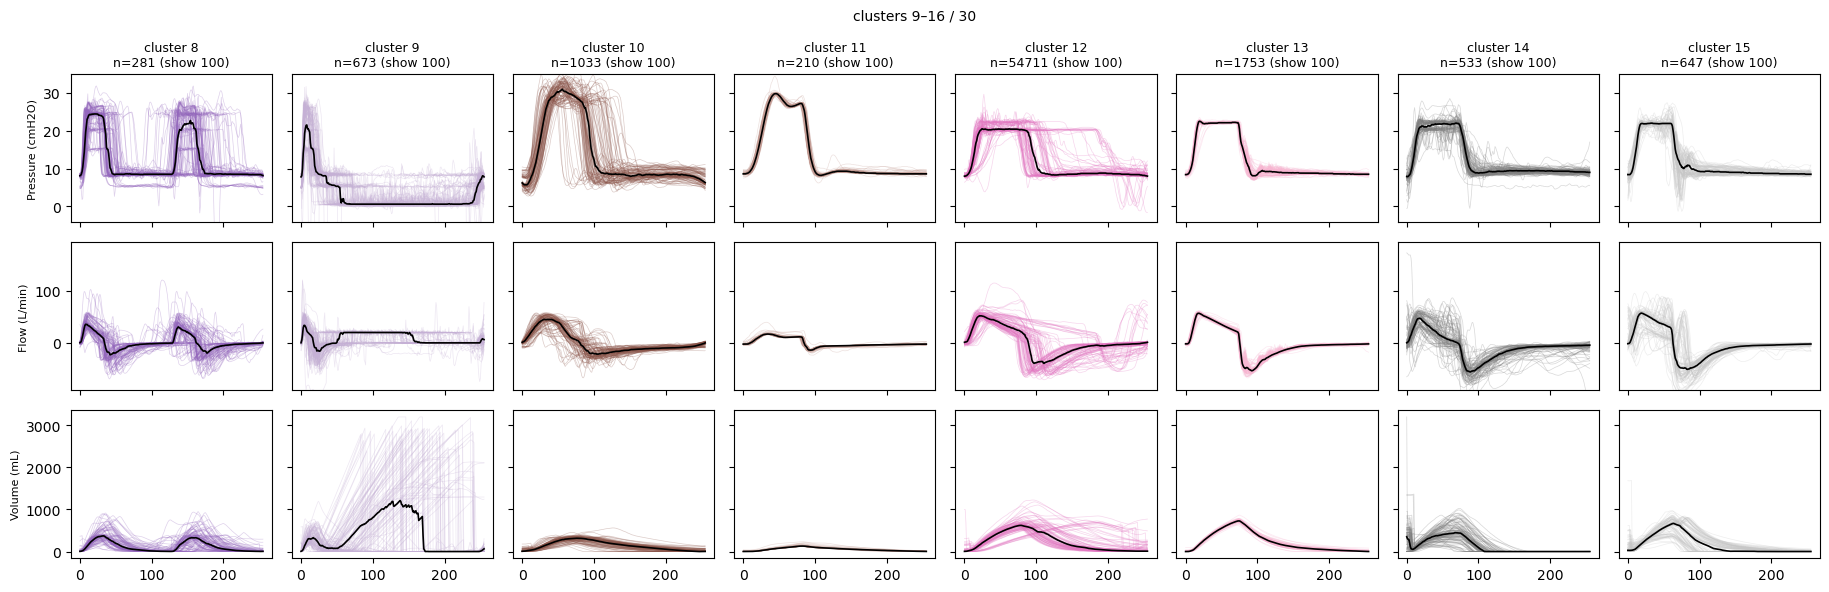

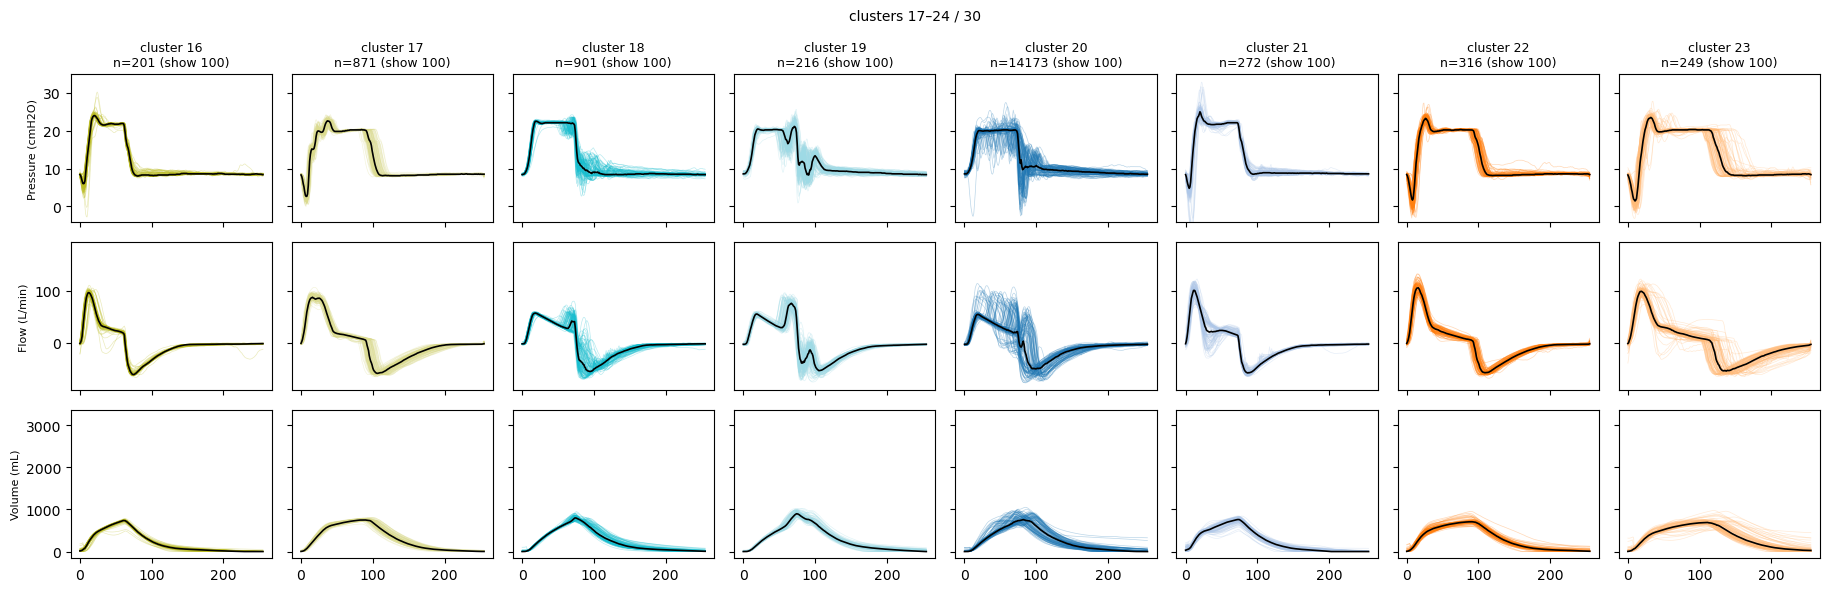

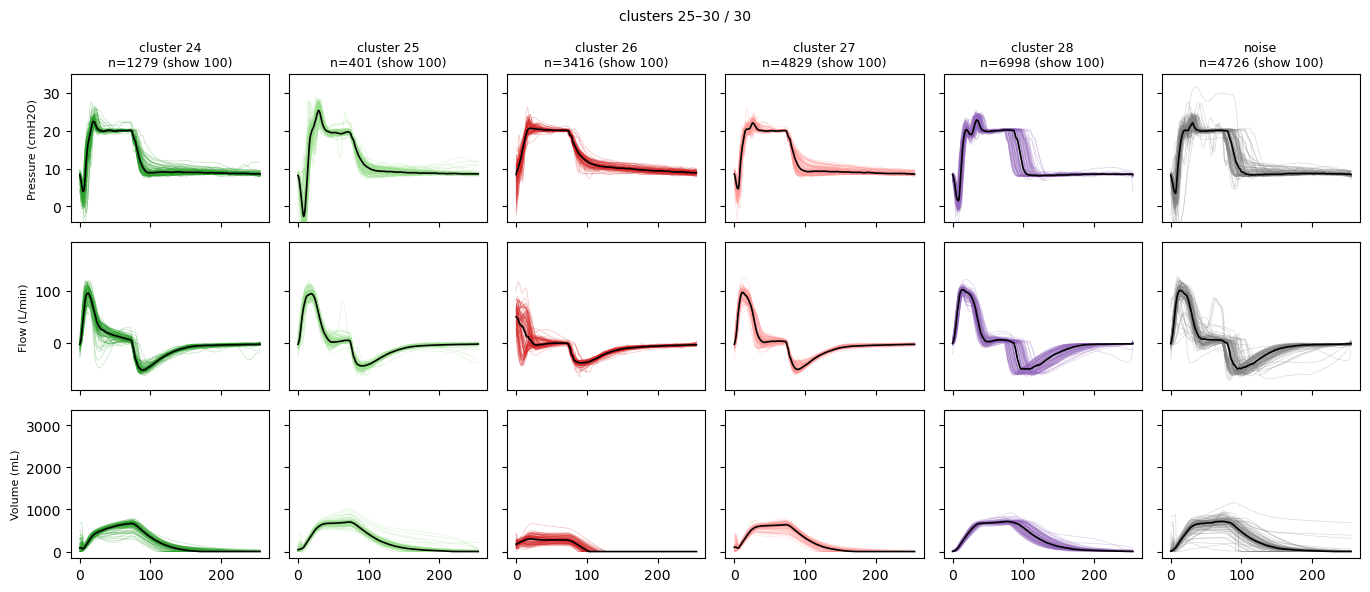

In [33]:
# 每群抽 N_PICK 口畫原始波形，黑線是中位數
PER_FIG = 8                                            # 每張圖放幾群
N_PICK  = 100                                           # 每群抽幾口來畫

# 資料夾名稱帶 latent 和 min_cluster_size；換資料要自己改名，不然會蓋掉
FIG_DIR = os.path.join("results", f"round2_Latent{Z.shape[1]}_ClusterSize{MIN_CLUSTER_SIZE}_Sample{N_PICK}")
os.makedirs(FIG_DIR, exist_ok=True)

show = list(range(n_clu)) + [-1]                       # 全部群（依群號）+ 雜訊

# 先抽好波形，y 範圍用 1～99 百分位，不然會被極端值壓扁
samples, ylim = {}, np.array([[np.inf, -np.inf]] * 3)
rng9 = np.random.default_rng()                         # 要固定抽樣就改 default_rng(0)
for c in show:
    members = fit_idx[lab_fit == c]
    if len(members) == 0: continue
    pick = np.sort(rng9.choice(members, size=min(N_PICK, len(members)), replace=False))
    w = np.asarray(X[pick])                            # (n, 3, L)
    samples[c] = (w, len(members))
    ylim[:, 0] = np.minimum(ylim[:, 0], np.percentile(w, 1,  axis=(0, 2)))
    ylim[:, 1] = np.maximum(ylim[:, 1], np.percentile(w, 99, axis=(0, 2)))
pad = (ylim[:, 1] - ylim[:, 0]) * 0.05

groups = [c for c in show if c in samples]
for p in range(0, len(groups), PER_FIG):
    page = groups[p:p + PER_FIG]
    fig, ax = plt.subplots(3, len(page), figsize=(2.3 * len(page), 6),
                           sharex=True, squeeze=False)
    for j, c in enumerate(page):
        w, n = samples[c]
        col = "0.5" if c < 0 else plt.cm.tab20(c % 20)
        for i in range(3):
            ax[i, j].plot(w[:, i].T, color=col, lw=0.5, alpha=0.3)          # 一次畫完
            ax[i, j].plot(np.median(w[:, i], axis=0), color="k", lw=1.2)   # 中位數
            ax[i, j].set_ylim(ylim[i, 0] - pad[i], ylim[i, 1] + pad[i])
            if j == 0: ax[i, j].set_ylabel(CH[i], fontsize=8)
            else:      ax[i, j].set_yticklabels([])
        ax[0, j].set_title(("noise" if c < 0 else f"cluster {c}")
                           + f"\nn={n} (show {len(w)})", fontsize=9)
    fig.suptitle(f"clusters {p + 1}–{p + len(page)} / {len(groups)}", fontsize=10)
    plt.tight_layout()

    fig.savefig(os.path.join(FIG_DIR, f"page{p // PER_FIG + 1:02d}_sample{N_PICK}.png"), dpi=150)
    plt.show()

In [23]:
# 每群的病人分布
patient_id = ids[:, 0]          # kb.csv 的 rec
assert len(lab_fit) == len(patient_id)

df = pd.DataFrame({"cluster": lab_fit, "patient": patient_id})
global_share = df["patient"].value_counts(normalize=True)
print("全部資料的病人比例：")
print(global_share.map("{:.2%}".format).to_string())

rows = []
for c, g in df[df["cluster"] >= 0].groupby("cluster"):
    p = g["patient"].value_counts(normalize=True)
    top_patient = p.index[0]
    rows.append({
        "cluster": c,
        "n": len(g),
        "n_patients": p.size,
        "top_patient": top_patient,
        "top_share": p.iloc[0],
        "global_share": global_share[top_patient],
        "lift": p.iloc[0] / global_share[top_patient],
        "effective_patients": np.exp(-(p * np.log(p)).sum()),
    })

summary = pd.DataFrame(rows).sort_values("n", ascending=False)
summary.to_csv("round2_cluster_patient_summary.csv", index=False)

n_specific = (summary["top_share"] > 0.8).sum()
print(f"\ntop_share > 80% 的群：{n_specific} / {len(summary)}")
print(summary["top_patient"].value_counts().to_string())

print("\n雜訊的病人比例：")
print(df.loc[df["cluster"] < 0, "patient"]
        .value_counts(normalize=True).map("{:.2%}".format).to_string())

print("\n最大的 20 群：")
print(summary.head(20).round(3).to_string(index=False))

全部資料的病人比例：
patient
1    90.71%
2     7.91%
4     1.21%
3     0.17%

top_share > 80% 的群：28 / 31
top_patient
1    18
2     9
4     3
3     1

雜訊的病人比例：
patient
2    49.28%
1    36.80%
4    13.92%

最大的 20 群：
 cluster     n  n_patients top_patient  top_share  global_share   lift  effective_patients
      13 54713           4           1      0.998         0.907  1.100               1.018
      22 21930           2           1      1.000         0.907  1.102               1.001
      20 14196           3           1      1.000         0.907  1.102               1.003
       5  5075           3           2      0.988         0.079 12.499               1.067
      25  1526           2           1      0.999         0.907  1.102               1.005
       3  1150           1           2      1.000         0.079 12.646               1.000
      19   901           1           1      1.000         0.907  1.102               1.000
      18   871           1           1      1.000         0.907  1.1

patient,n,1,2,3,4,top_patient,top_share
cluster,,,,,,,
noise,625,36.80,49.28,0.00,13.92,2,49.28
0,257,0.00,100.00,0.00,0.00,2,100.00
1,178,0.00,0.00,97.19,2.81,3,97.19
2,644,0.00,0.00,0.31,99.69,4,99.69
3,1150,0.00,100.00,0.00,0.00,2,100.00
4,159,97.48,0.00,0.00,2.52,1,97.48
5,5075,1.12,98.84,0.00,0.04,2,98.84
6,582,100.00,0.00,0.00,0.00,1,100.00
7,365,9.59,44.38,0.00,46.03,4,46.03


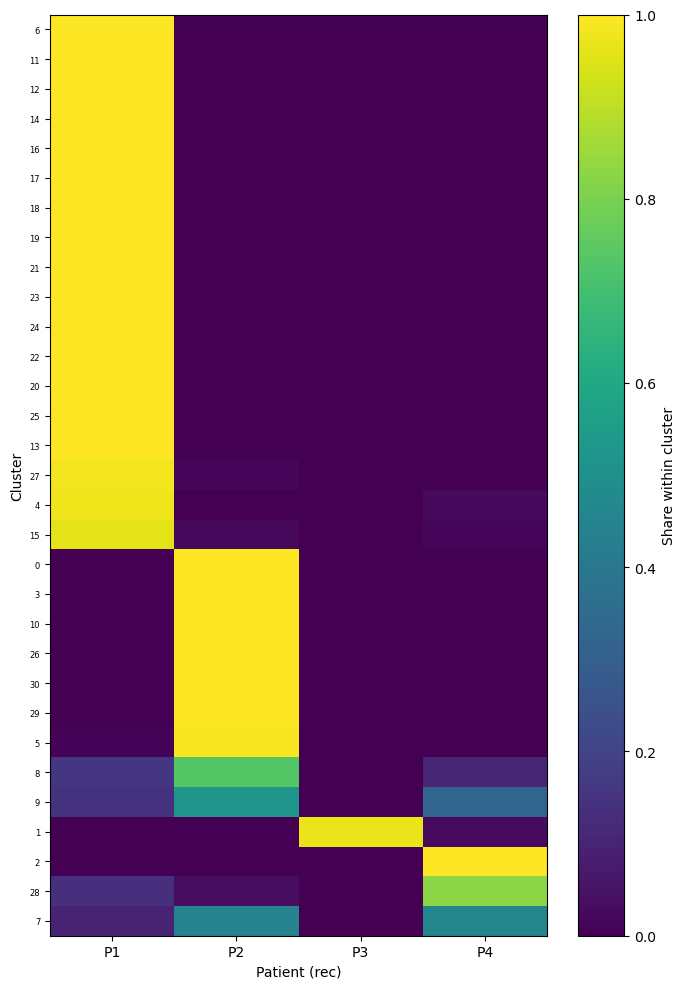

In [24]:
# 每群各病人的比例
patient_id = ids[:, 0].astype(str)

counts = pd.crosstab(lab_fit, patient_id)
counts.index.name = "cluster"
counts.columns.name = "patient"
counts = counts[sorted(counts.columns, key=int)]

ratio = counts.div(counts.sum(axis=1), axis=0)

table = (ratio * 100).round(2)
table.insert(0, "n", counts.sum(axis=1))
table["top_patient"] = ratio.idxmax(axis=1)
table["top_share"] = (ratio.max(axis=1) * 100).round(2)
table = table.rename(index={-1: "noise"})

table.to_csv("round2_cluster_patient_ratio.csv", encoding="utf-8-sig")

# 全部印出來
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200):
    display(table)

# 熱圖：主要病人一樣的群排在一起，再照占比排
clusters_only = ratio.drop(index=-1, errors="ignore")
order = (
    clusters_only.assign(
        top_patient=clusters_only.idxmax(axis=1),
        top_share=clusters_only.max(axis=1),
    )
    .sort_values(["top_patient", "top_share"], ascending=[True, False])
    .index
)

plot_data = clusters_only.loc[order]
fig, ax = plt.subplots(figsize=(7, max(10, len(plot_data) * 0.16)))
im = ax.imshow(plot_data.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(plot_data.shape[1]))
ax.set_xticklabels([f"P{p}" for p in plot_data.columns])
ax.set_yticks(range(plot_data.shape[0]))
ax.set_yticklabels(plot_data.index, fontsize=6)
ax.set_xlabel("Patient (rec)")
ax.set_ylabel("Cluster")
fig.colorbar(im, ax=ax, label="Share within cluster")
plt.tight_layout()

         count   mean    std    min    25%    50%    75%    max
patient                                                        
1         18.0  0.624  0.321  0.041  0.386  0.628  0.932  1.000
2          9.0  0.424  0.407  0.000  0.001  0.328  0.763  1.000
3          1.0  1.000    NaN  1.000  1.000  1.000  1.000  1.000
4          3.0  0.952  0.058  0.887  0.931  0.975  0.985  0.995


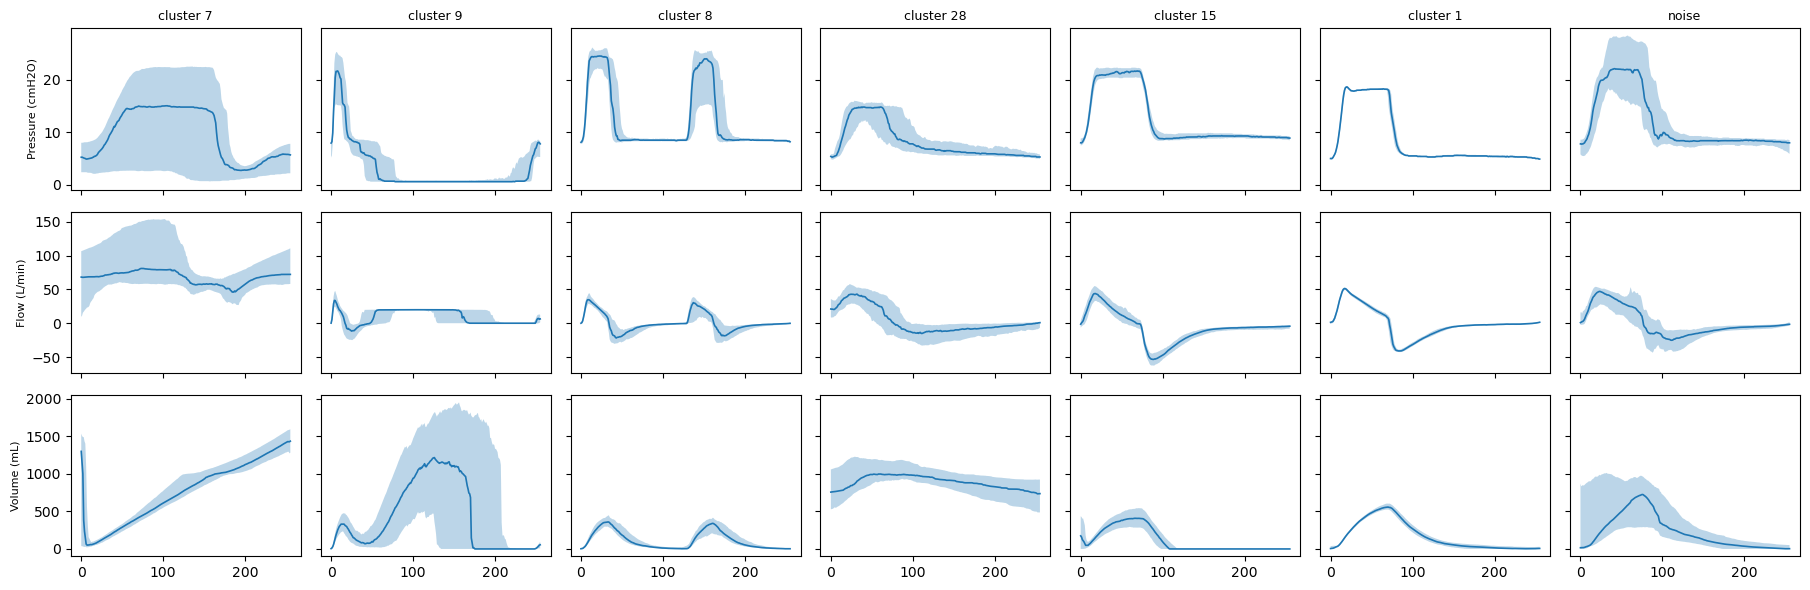

In [25]:
meta = pd.DataFrame({
    "cluster": lab_fit,
    "patient": ids[:, 0].astype(str),
    "breath_id": kb["breath_id"].to_numpy(),
    "mse": scores,
    "length": lens,
})

time_rows = []
for c, g in meta[meta["cluster"] >= 0].groupby("cluster"):
    top_patient = g["patient"].mode().iloc[0]
    g_top = g[g["patient"] == top_patient]
    all_top = meta.loc[meta["patient"] == top_patient, "breath_id"]
    span = np.ptp(g_top["breath_id"]) / max(np.ptp(all_top), 1)
    time_rows.append({
        "cluster": c,
        "n": len(g),
        "patient": top_patient,
        "time_span": span,
        "median_mse": g["mse"].median(),
        "median_length": g["length"].median(),
    })

time_df = pd.DataFrame(time_rows).sort_values(["patient", "time_span"])
time_df.to_csv("round2_cluster_time_span.csv", index=False)
print(time_df.groupby("patient")["time_span"].describe().round(3))

# 跨病人群與雜訊的代表波形
# 挑病人最混的 6 群，加上雜訊
_ts = pd.crosstab(lab_fit[lab_fit >= 0], ids[lab_fit >= 0, 0], normalize="index").max(axis=1)
show = _ts.sort_values().index[:6].tolist() + [-1]
rng_show = np.random.default_rng(0)
fig, ax = plt.subplots(3, len(show), figsize=(2.6 * len(show), 6), sharex=True, sharey="row")

for j, c in enumerate(show):
    idx = np.flatnonzero(lab_fit == c)
    pick = np.sort(rng_show.choice(idx, min(300, len(idx)), replace=False))
    w = np.asarray(X[pick])
    for i in range(3):
        q25, q50, q75 = np.percentile(w[:, i], [25, 50, 75], axis=0)
        ax[i, j].fill_between(range(L), q25, q75, alpha=0.3)
        ax[i, j].plot(q50, lw=1.2)
    ax[0, j].set_title("noise" if c < 0 else f"cluster {c}", fontsize=9)

for i, name in enumerate(CH):
    ax[i, 0].set_ylabel(name, fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# # HDBSCAN 分群
# MIN_CLUSTER_SIZE = 50    
# MIN_SAMPLES      = None     

# hdb = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
# lab_fit = hdb.fit_predict(E_fit)                       # 群號，-1 = 雜訊
# n_clu = lab_fit.max() + 1

# print(f"群數 = {n_clu}，雜訊 = {(lab_fit < 0).sum()} 口（{(lab_fit < 0).mean():.2%}）")
# print(pd.Series(lab_fit, name="口數").value_counts().sort_index().to_string())

## 10. 跟第一輪群號對照

看第二輪每群主要來自第一輪哪幾群，還有第一輪的群有沒有被拆開。

In [26]:
# 第二輪群對第一輪群
# stage1_cluster 是第一輪的群號，-1 是雜訊
s1 = kb["stage1_cluster"].to_numpy()
ct = pd.crosstab(pd.Series(lab_fit, name="round2"), pd.Series(s1, name="stage1"))

rows = []
for c2, r in ct.iterrows():
    top = r.sort_values(ascending=False)
    rows.append({
        "round2": "noise" if c2 < 0 else c2,
        "n": int(r.sum()),
        "n_stage1": int((r > 0).sum()),                    # 由幾個第一輪的群組成
        "top_stage1": "noise" if top.index[0] < 0 else top.index[0],
        "top_share": top.iloc[0] / r.sum(),
        "from_stage1_noise": (r.get(-1, 0)) / r.sum(),     # 來自第一輪雜訊的比例
    })
map_df = pd.DataFrame(rows)
map_df.to_csv("round2_vs_stage1.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_rows", None, "display.width", 200):
    display(map_df.round(3))

# 第一輪的群在第二輪拆成幾群（>= 5% 才算）
split = (ct.drop(index=-1, errors="ignore") / ct.sum(axis=0)).ge(0.05).sum(axis=0)
big = ct.sum(axis=0).sort_values(ascending=False).head(15).index
print("第一輪最大的 15 群，在第二輪各被拆成幾群（占該群 >= 5% 才算）：")
print(pd.DataFrame({"n": ct.sum(axis=0)[big], "n_round2_clusters": split[big],
                    "to_round2_noise": (ct.loc[-1] / ct.sum(axis=0))[big].round(3) if -1 in ct.index else 0}).to_string())


,round2,n,n_stage1,top_stage1,top_share,from_stage1_noise
0,noise,625,8,5,0.347,0.218
1,0,257,2,noise,0.996,0.996
2,1,178,1,noise,1.000,1.000
3,2,644,2,15,0.935,0.065
4,3,1150,1,13,1.000,0.000
5,4,159,1,1,1.000,0.000
6,5,5075,2,2,0.998,0.002
7,6,582,2,noise,0.976,0.976
8,7,365,3,22,0.595,0.403
9,8,281,2,11,0.996,0.000


第一輪最大的 15 群，在第二輪各被拆成幾群（占該群 >= 5% 才算）：
            n  n_round2_clusters  to_round2_noise
stage1                                           
-1      29958                  3            0.005
 49     28669                  1            0.000
 47      6965                  1            0.000
 37      6459                  1            0.000
 46      5108                  1            0.000
 2       5075                  1            0.000
 23      3523                  1            0.000
 35      1375                  2            0.000
 34      1316                  1            0.000
 43      1169                  1            0.000
 13      1150                  1            0.000
 59      1059                  1            0.001
 42      1054                  1            0.000
 27      1050                  1            0.000
 5       1016                  3            0.214
